In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import sys
sys.path.insert(0, os.path.abspath("../.."))

In [3]:
# 1 imports and paths
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import gc

gc.enable()

import torch
from src.config import EXP_CONFIGS
from src.utils import set_seed, save_config

main_folder = "../.."
exp_name = (
    "exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights"
)
img_folder  = os.path.join(main_folder, "data", "train")
out_dir     = os.path.join(main_folder, "outputs", "extra", "exp18_aux_heads_metadata_weightedBCELoss",exp_name)
out_csv     = os.path.join(main_folder, "data", "train.csv")

os.makedirs(out_dir, exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/home/ghias/miniconda3/envs/rapids-env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
#  generate aux-labels if not already done, load CSV, set cfg
from src.utils import build_binary_aux_cfg
import sys
sys.path.insert(0, os.path.join(main_folder))

TARGET = "Pawpularity"
df = pd.read_csv(os.path.join(main_folder, "data", "train.csv"))

# --- set cfg ---
cfg = EXP_CONFIGS["exp15_aux_brisque"].copy()
cfg["img_size"] = 384
cfg["name"]     = exp_name
cfg["loss"]     = "mse"
cfg["head_type"] = "mlp"#strong head , linear or mlp
cfg["aux_tasks"]          = []                    # no regression aux
cfg["binary_aux_tasks"]   = ["Eyes","Face","Occlusion", "Blur",
                             "Subject Focus","Action","Accessory",
                             "Near", "Group","Collage","Human", "Info"]  # all 12 binary aux tasks
cfg["aux_loss_weights"]   = {
    "Face":      0.1,
    "Eyes":      0.1,
    "Occlusion": 0.1,
    "Blur":      0.1,
    "Subject Focus": 0.1,
    "Action": 0.1,
    "Accessory": 0.1,
    "Group": 0.1,
    "Collage": 0.1,
    "Human": 0.1,
    "Info": 0.1,
    "Near": 0.1
}


cfg["binary_aux_loss_type"] = "weighted_bce"

# pos_weight  = majority_count / minority_count  -> passed to BCEWithLogitsLoss to
#               up-weight the rare class during training.
# flip_targets = tasks where class 0 is the minority; labels are flipped to 1
#               so BCE always treats the minority as the positive class.because PyTorch's pos_weight only applies
#               to label=1 samples  without flipping it would have no effect on
#               the minority class when it is label 0
# pos_weight_dict, flip_targets_list = build_binary_aux_cfg(df, cfg["binary_aux_tasks"])
# print("pos_weight_dict:", pos_weight_dict, "flip_targets_list:", flip_targets_list)
# cfg["binary_aux_pos_weight"]   = pos_weight_dict
# cfg["binary_aux_flip_targets"] = flip_targets_list

# Calculated separately from each fold's training labels.
cfg["binary_aux_pos_weight"] = {}
cfg["binary_aux_flip_targets"] = []

# Used later to load the matching fold-specific configuration.
cfg["binary_aux_config_scope"] = "per_fold_training"

# Verify that every intended task appears exactly once.
assert len(cfg["binary_aux_tasks"]) == 12
assert len(set(cfg["binary_aux_tasks"])) == 12

cfg["use_saliency"]       = False

save_config(cfg, out_dir)
set_seed(cfg["seed"])



In [5]:

from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_error
from src.train import run_single_fold
import time
import copy
import json

kf = KFold(n_splits=cfg["n_splits"], shuffle=True, random_state=cfg["seed"])
oof_pred = np.zeros(len(df))
oof_true = df[TARGET].values
fold_index = np.full(len(df), -1, dtype=int)
fold_rmse = []

start_all = time.time()
for fold, (tr_idx, val_idx) in enumerate(kf.split(df), start=1):
    print(f"\n=== {cfg['name']}: Fold {fold} ===")
    train_df = df.iloc[tr_idx].reset_index(drop=True)
    val_df   = df.iloc[val_idx].reset_index(drop=True)

    # Independent settings for this fold.
    fold_cfg = copy.deepcopy(cfg)
    # Calculate weights and label encoding from TRAINING data only.
    pos_weight_dict, flip_targets_list = build_binary_aux_cfg(
        train_df,
        fold_cfg["binary_aux_tasks"],
    )

    fold_cfg["binary_aux_pos_weight"] = pos_weight_dict
    fold_cfg["binary_aux_flip_targets"] = flip_targets_list

    print("Training-fold weights:", pos_weight_dict)
    print("Training-fold flipped tasks:", flip_targets_list)

    # Save the encoding needed to interpret this checkpoint later.
    fold_config_path = os.path.join(
        out_dir, f"config_fold{fold}.json"
    )

    with open(fold_config_path, "w") as f:
        json.dump(fold_cfg, f, indent=2)

    best_rmse, val_preds, val_targets, val_ids = run_single_fold(
        fold=fold,
        train_df=train_df,
        val_df=val_df,
        img_folder=img_folder,
        cfg=fold_cfg,
        out_dir=out_dir,
        device=device,
        mode="image",
        tab_cols=None,
        workers=16,
        pin_memory=True,
        persistent_workers=True,
    )

    oof_pred[val_idx] = val_preds
    fold_index[val_idx] = fold
    fold_rmse.append(best_rmse)
    print(f"Fold {fold} best RMSE: {best_rmse:.4f}")


all_sec = time.time() - start_all
print(f"\nTotal training time: {int(all_sec//60)}m {int(all_sec%60)}s")
# final metrics + OOF with fold column
oof_rmse = root_mean_squared_error(oof_true, oof_pred)
fold_rmse = np.array(fold_rmse)
print(f"\nOOF RMSE: {oof_rmse:.4f}")
print(f"Fold RMSEs: {fold_rmse.tolist()}  Mean={fold_rmse.mean():.4f}  Std={fold_rmse.std():.4f}")

oof_df = pd.DataFrame({
    "Id": df["Id"],
    "fold": fold_index,      
    "ytrue": oof_true,
    "oof_pred": oof_pred,
})
oof_df["abs_err"] = (oof_df["ytrue"] - oof_df["oof_pred"]).abs()
oof_df.to_csv(os.path.join(out_dir, "oof_detail.csv"), index=False)
oof_df.sort_values("abs_err", ascending=False).head(50).to_csv(
    os.path.join(out_dir, "top50_errors.csv"), index=False
)

np.save(os.path.join(out_dir, "oof_pred.npy"), oof_pred)
np.save(os.path.join(out_dir, "fold_rmse.npy"), fold_rmse)
with open(os.path.join(out_dir, "metrics.txt"), "w") as f:
    f.write(f"OOF_RMSE: {oof_rmse:.4f}\n")
    f.write(f"Fold_RMSE: {fold_rmse.tolist()}\nMean: {fold_rmse.mean():.4f}\nStd: {fold_rmse.std():.4f}\n")



=== exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights: Fold 1 ===
  Eyes: class_0=1823, class_1=6106   minority=class_0, flip target, pos_weight=3.35
  Face: class_0=778, class_1=7151   minority=class_0, flip target, pos_weight=9.19
  Occlusion: class_0=6555, class_1=1374   minority=class_1, pos_weight=4.77
  Blur: class_0=7348, class_1=581   minority=class_1, pos_weight=12.65
  Subject Focus: class_0=7699, class_1=230   minority=class_1, pos_weight=33.47
  Action: class_0=7851, class_1=78   minority=class_1, pos_weight=100.65
  Accessory: class_0=7394, class_1=535   minority=class_1, pos_weight=13.82
  Near: class_0=1073, class_1=6856   minority=class_0, flip target, pos_weight=6.39
  Group: class_0=6914, class_1=1015   minority=class_1, pos_weight=6.81
  Collage: class_0=7538, class_1=391   minority=class_1, pos_weight=19.28
  Human: class_0=6589, class_1=1340   minority=class_1, pos_weight=4.92
  Info: class_0=7448, class_1=481   minority=class_1, pos_weight=15.48
Training-fold

Epoch 1/10 | Fold 1 | Train[MSE]: PawRMSE=23.7853 TotalLoss=567.2578 | ValRMSE: 21.0473 | train_loss_Eyes: 1.0755 | train_loss_Face: 1.2670 | train_loss_Occlusion: 1.1561 | train_loss_Blur: 1.3062 | train_loss_Subject Focus: 1.3728 | train_loss_Action: 1.4321 | train_loss_Accessory: 1.3102 | train_loss_Near: 1.2108 | train_loss_Group: 1.2206 | train_loss_Collage: 1.3380 | train_loss_Human: 1.1616 | train_loss_Info: 1.3175 | train_train_acc_Eyes: 0.5165 | train_train_acc_Face: 0.4603 | train_train_acc_Occlusion: 0.5326 | train_train_acc_Blur: 0.6016 | train_train_acc_Subject Focus: 0.5242 | train_train_acc_Action: 0.5994 | train_train_acc_Accessory: 0.4839 | train_train_acc_Near: 0.4936 | train_train_acc_Group: 0.5003 | train_train_acc_Collage: 0.5583 | train_train_acc_Human: 0.4761 | train_train_acc_Info: 0.4405 | Eyes_val_bce: 0.7360 | Eyes_val_acc: 0.2173 | Eyes_val_f1: 0.0000 | Eyes_val_prec: 0.0000 | Eyes_val_rec: 0.0000 | Face_val_bce: 0.5227 | Face_val_acc: 0.9123 | Face_val_f1: 

In [6]:
from src.utils import extract_aux_oof_to_csv

# Reload the original data, including the 12 semantic labels.
df_for_extraction = pd.read_csv(
    os.path.join(main_folder, "data", "train.csv")
)

aux_oof_df = extract_aux_oof_to_csv(
    out_dir=out_dir,
    df=df_for_extraction,
    img_folder=img_folder,
    cfg=cfg,
    force=True,
    device=device,
)

display(aux_oof_df.head())

fold 1: extracted 1983 samples
fold 2: extracted 1983 samples
fold 3: extracted 1982 samples
fold 4: extracted 1982 samples
fold 5: extracted 1982 samples

Saved: ../../outputs/extra/exp18_aux_heads_metadata_weightedBCELoss/exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights/oof_detail_aux.csv


,Id,fold,ytrue,Eyes_true,Eyes_prob,Eyes_pred_05,Face_true,Face_prob,Face_pred_05,Occlusion_true,...,Group_pred_05,Collage_true,Collage_prob,Collage_pred_05,Human_true,Human_prob,Human_pred_05,Info_true,Info_prob,Info_pred_05
0,0007de18844b0dbbb5e1f607da0606e0,1,63.0,1,0.486490,0,1,0.504054,1,0,...,0,0,0.515027,1,0,0.554140,1,0,0.517755,1
1,0018df346ac9c1d8413cfcc888ca8246,1,15.0,1,0.501516,1,1,0.549152,1,0,...,0,0,0.475524,0,0,0.555141,1,0,0.492548,0
2,0042bc5bada6d1cf8951f8f9f0d399fa,1,53.0,1,0.524715,1,1,0.617910,1,0,...,0,0,0.428254,0,0,0.505244,1,0,0.485125,0
3,005017716086b8d5e118dd9fe26459b1,1,28.0,1,0.659753,1,1,0.683242,1,0,...,0,0,0.467999,0,0,0.468983,0,0,0.469824,0
4,00630b1262efe301cb15a3b2022ba744,1,18.0,1,0.579354,1,1,0.602671,1,0,...,0,0,0.488145,0,0,0.423020,0,0,0.475192,0


In [7]:

import pandas as pd
df = pd.read_csv(out_dir+"/oof_detail.csv")
fold_rmse = []

for fold in range(1, 6):
    sub = df[df.fold == fold]
    rmse = ((sub.ytrue - sub.oof_pred)**2).mean() ** 0.5
    fold_rmse.append(rmse)
    print(f"Fold {fold} OOF RMSE: {rmse:.4f} (n={len(sub)})")

Fold 1 OOF RMSE: 17.7358 (n=1983)
Fold 2 OOF RMSE: 17.9753 (n=1983)
Fold 3 OOF RMSE: 17.4097 (n=1982)
Fold 4 OOF RMSE: 17.4662 (n=1982)
Fold 5 OOF RMSE: 18.0989 (n=1982)


In [8]:
# aux-task validation metrics 



baseline_rmse_path = os.path.join(
    "../..", "outputs", "extra", "exp3_swin_384_strong_MSE_MLPHead", "fold_rmse.npy"
)
aux_rmse_path = os.path.join(out_dir, "fold_rmse.npy")

if os.path.exists(baseline_rmse_path) and os.path.exists(aux_rmse_path):
    fold_rmse_base = np.load(baseline_rmse_path)
    fold_rmse_aux  = np.load(aux_rmse_path)

    print(f"\n{'Model':<35} {'Mean':>7} {'Std':>6}  Fold RMSEs")
    print(f"{'Swin image-only (exp3)':<35} "
          f"{fold_rmse_base.mean():>7.4f} {fold_rmse_base.std():>6.4f}  "
          f"{[round(x,4) for x in fold_rmse_base.tolist()]}")
    print(f"{'Swin + Blur aux (exp18)':<35} "
          f"{fold_rmse_aux.mean():>7.4f} {fold_rmse_aux.std():>6.4f}  "
          f"{[round(x,4) for x in fold_rmse_aux.tolist()]}")

    


Model                                  Mean    Std  Fold RMSEs
Swin image-only (exp3)              17.7337 0.2876  [17.7702, 18.0767, 17.3341, 17.4841, 18.0031]
Swin + Blur aux (exp18)             17.7372 0.2714  [17.7358, 17.9753, 17.4097, 17.4662, 18.0989]


### Training and Validation Loss Curve

In [9]:
from src.plot import plot_train_val_history
out_dir1 = os.path.join("../..", "outputs","extra", "exp3_swin_384_strong_MSE_MLPHead")


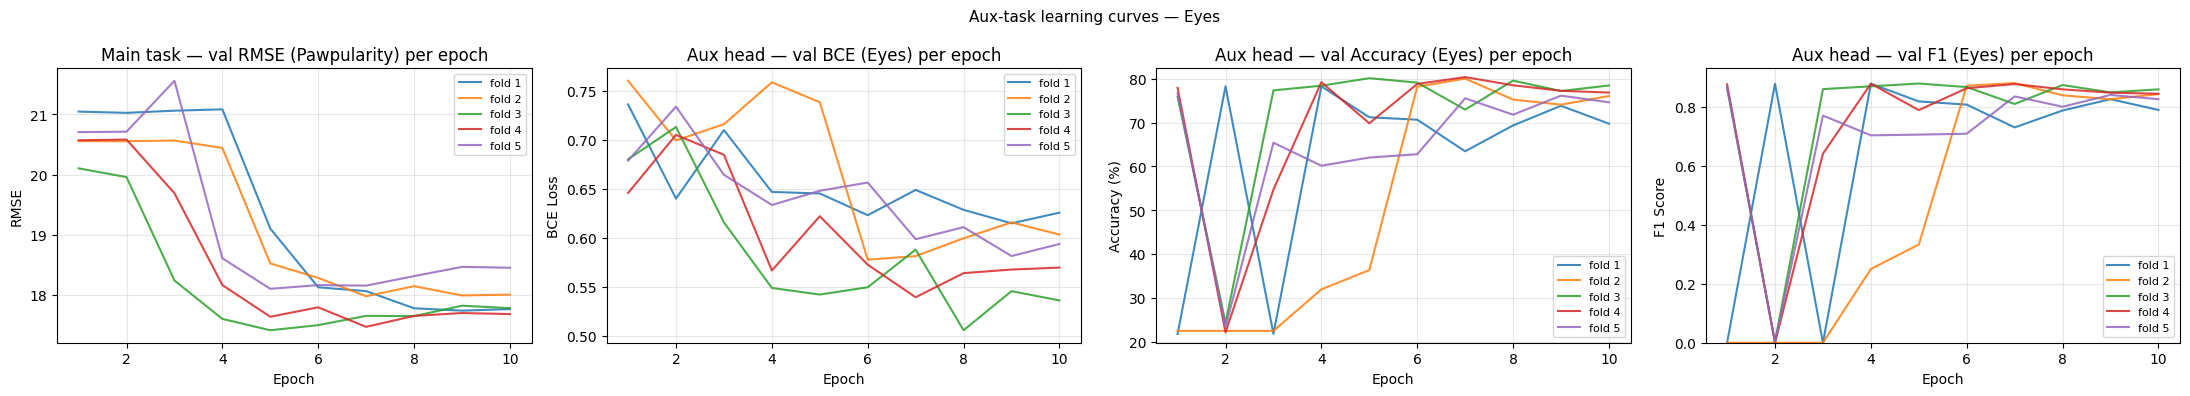

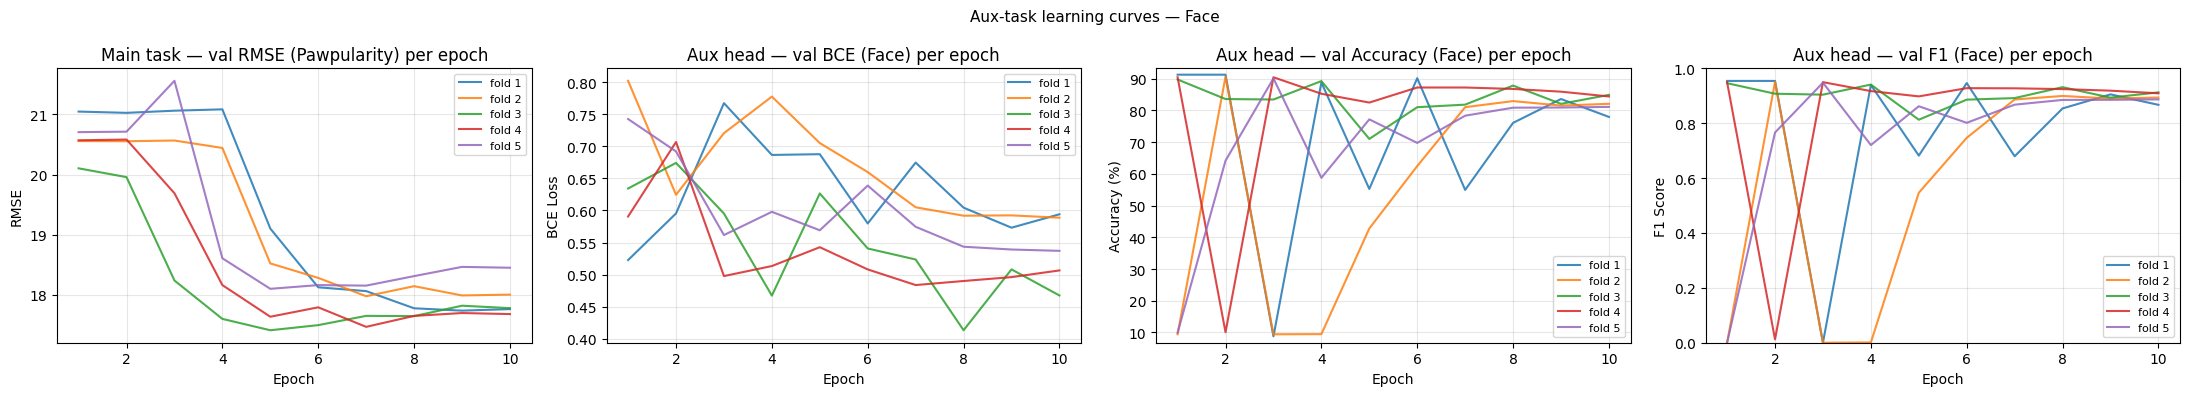

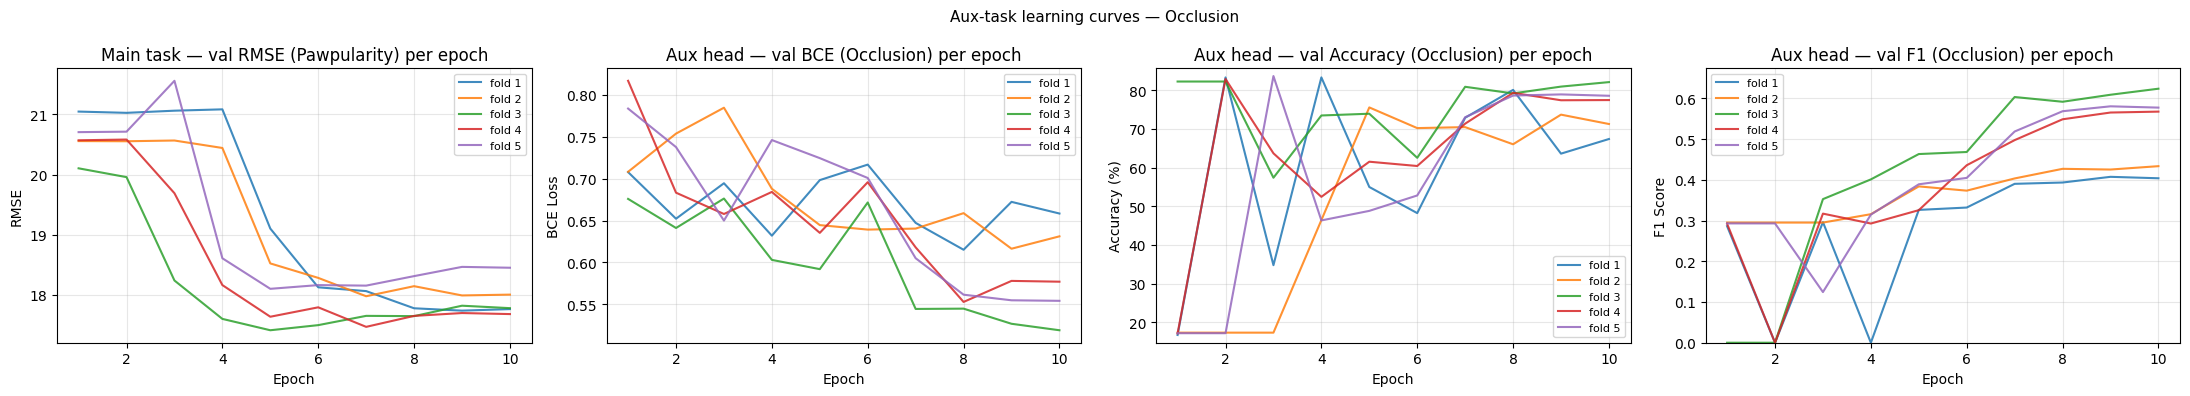

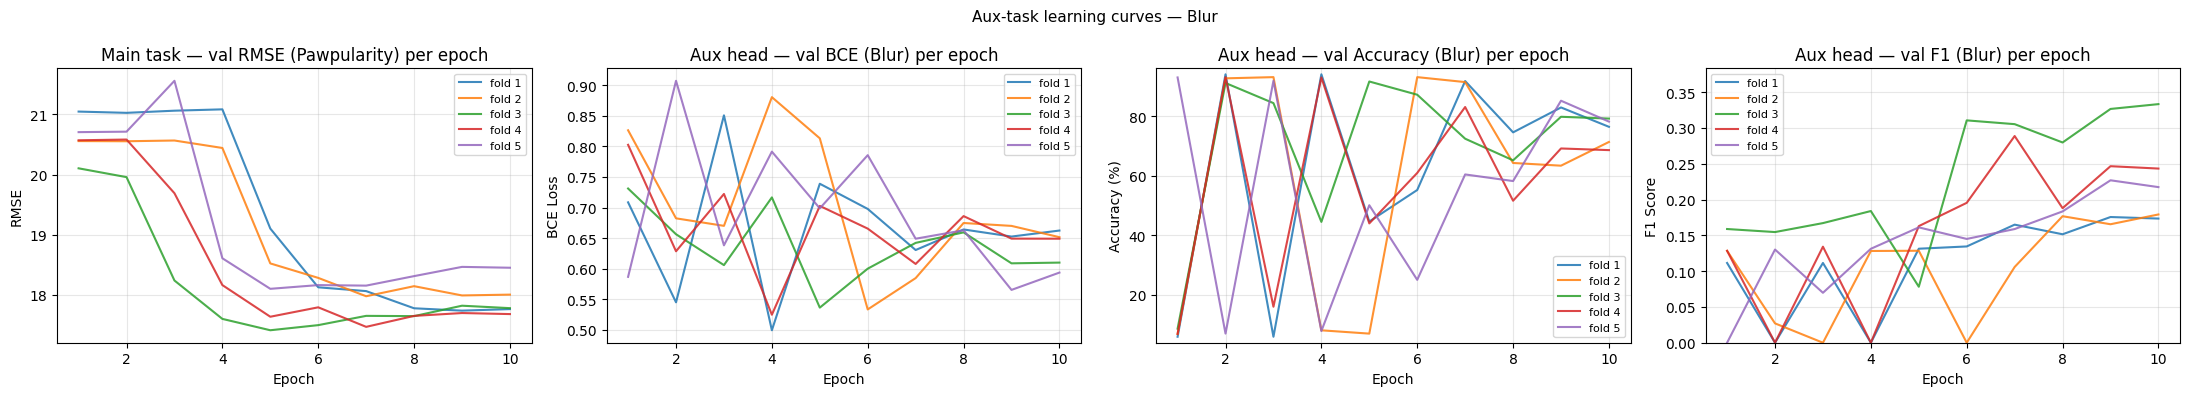

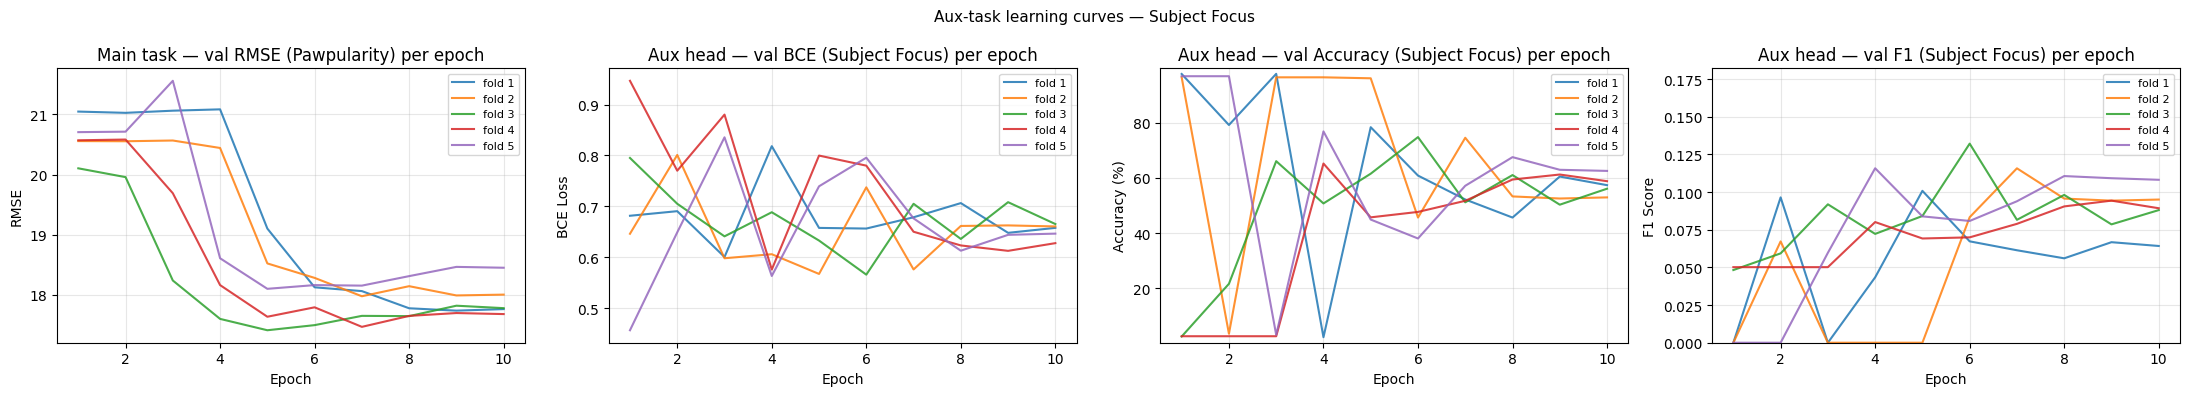

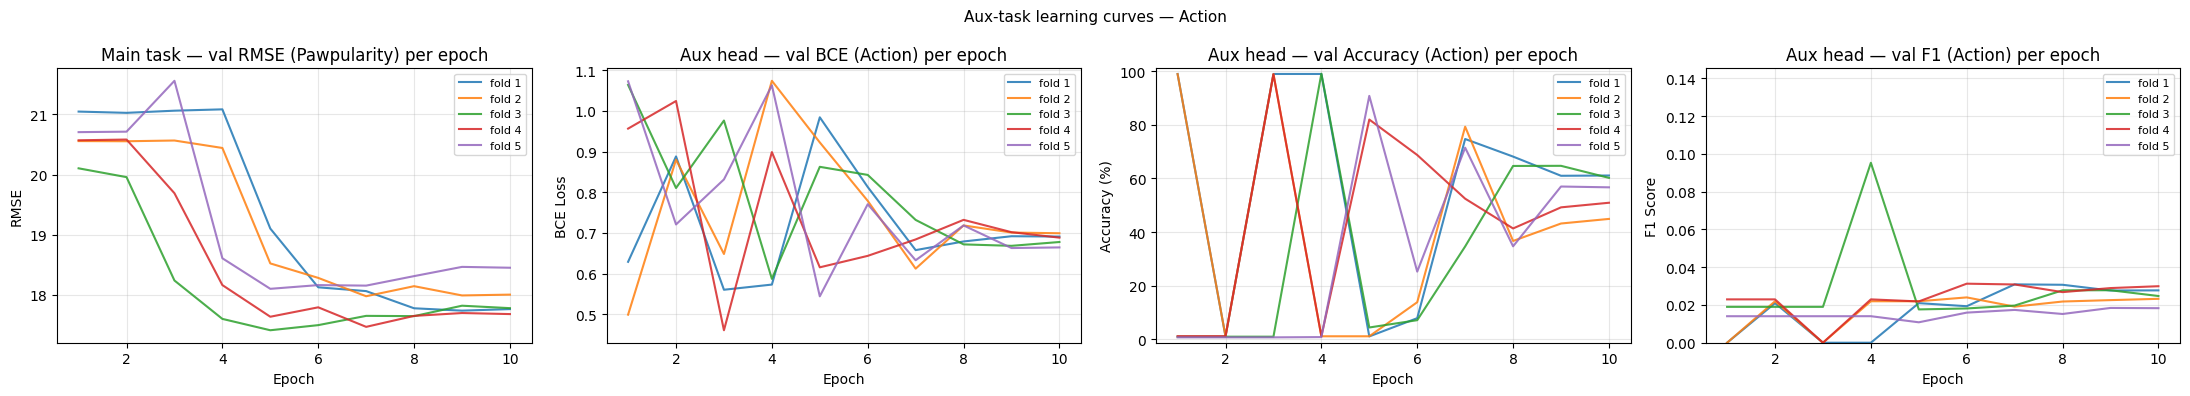

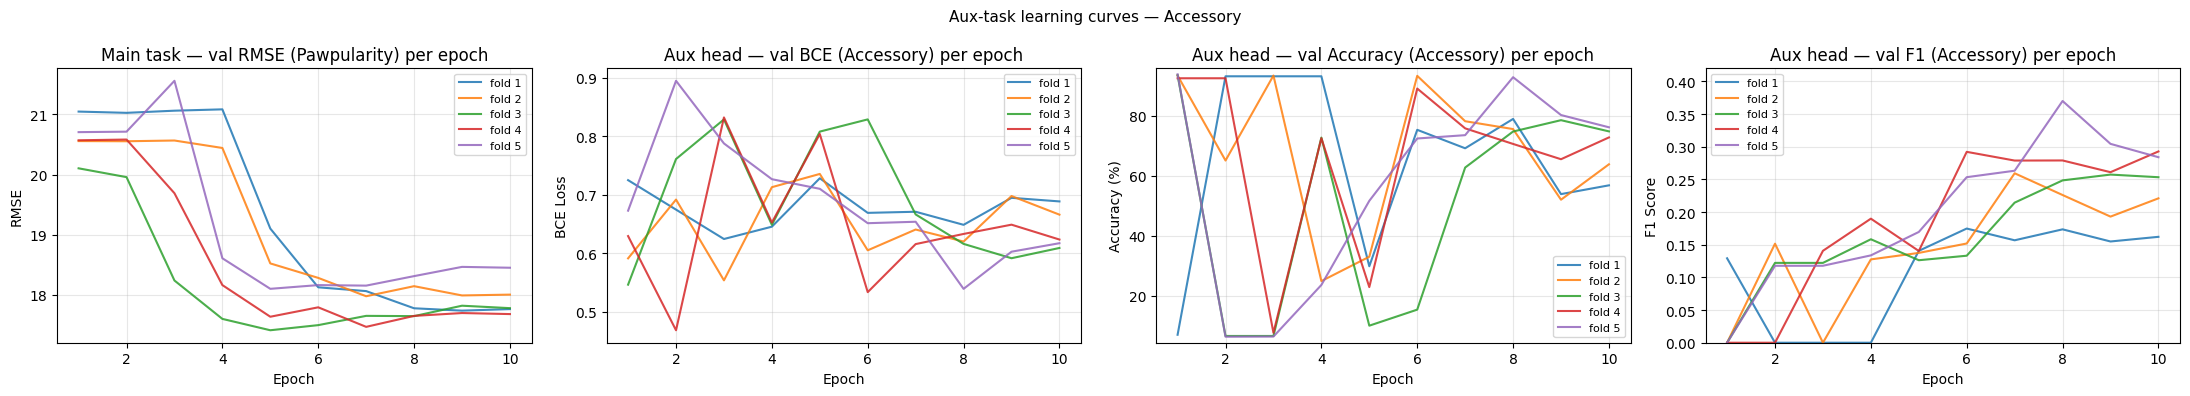

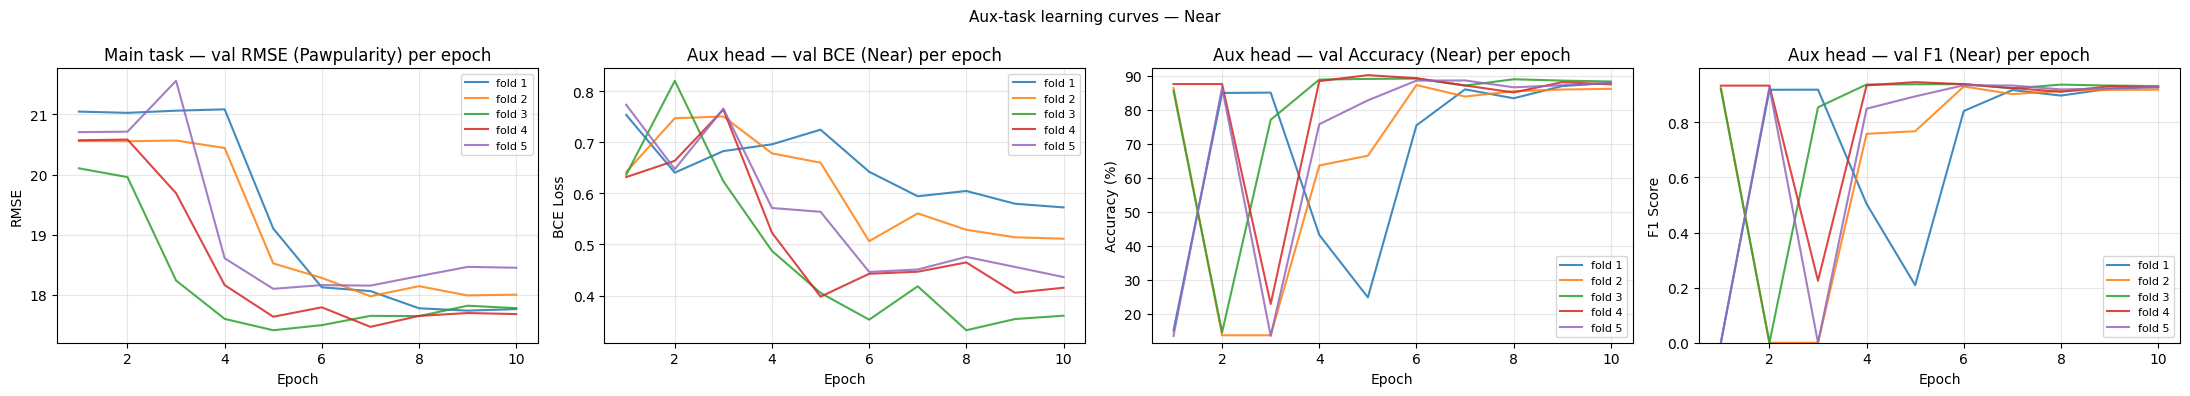

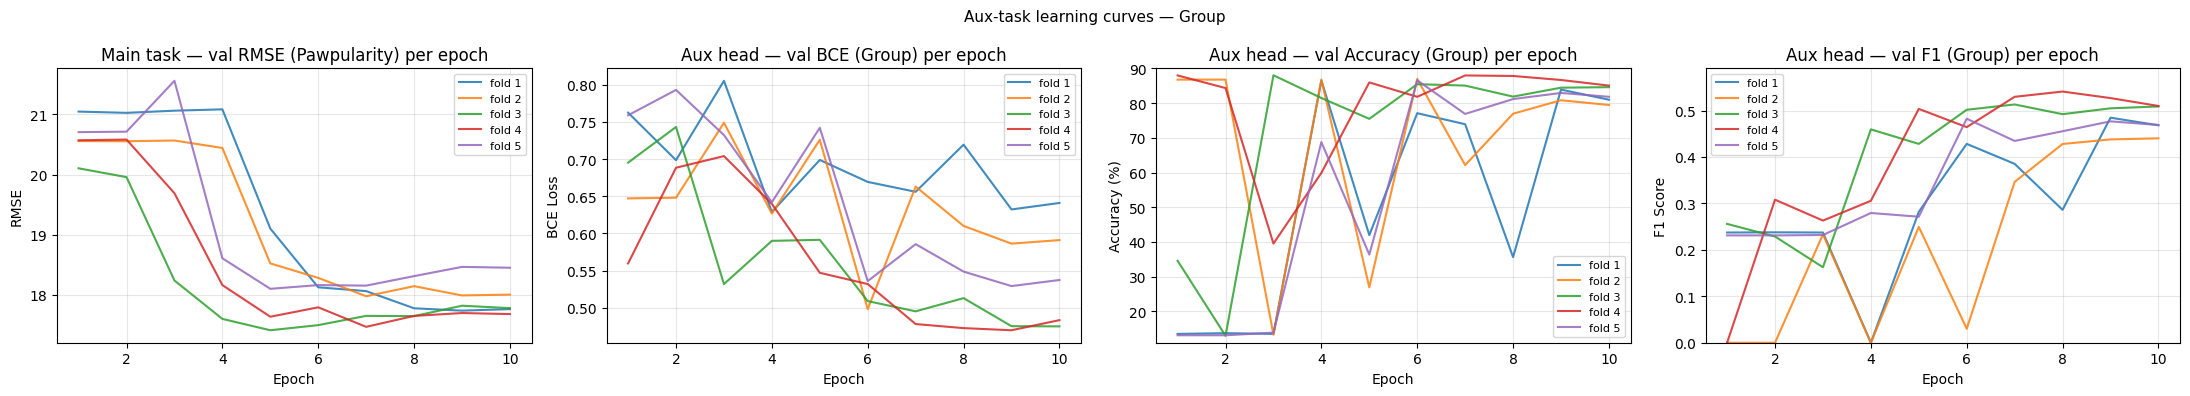

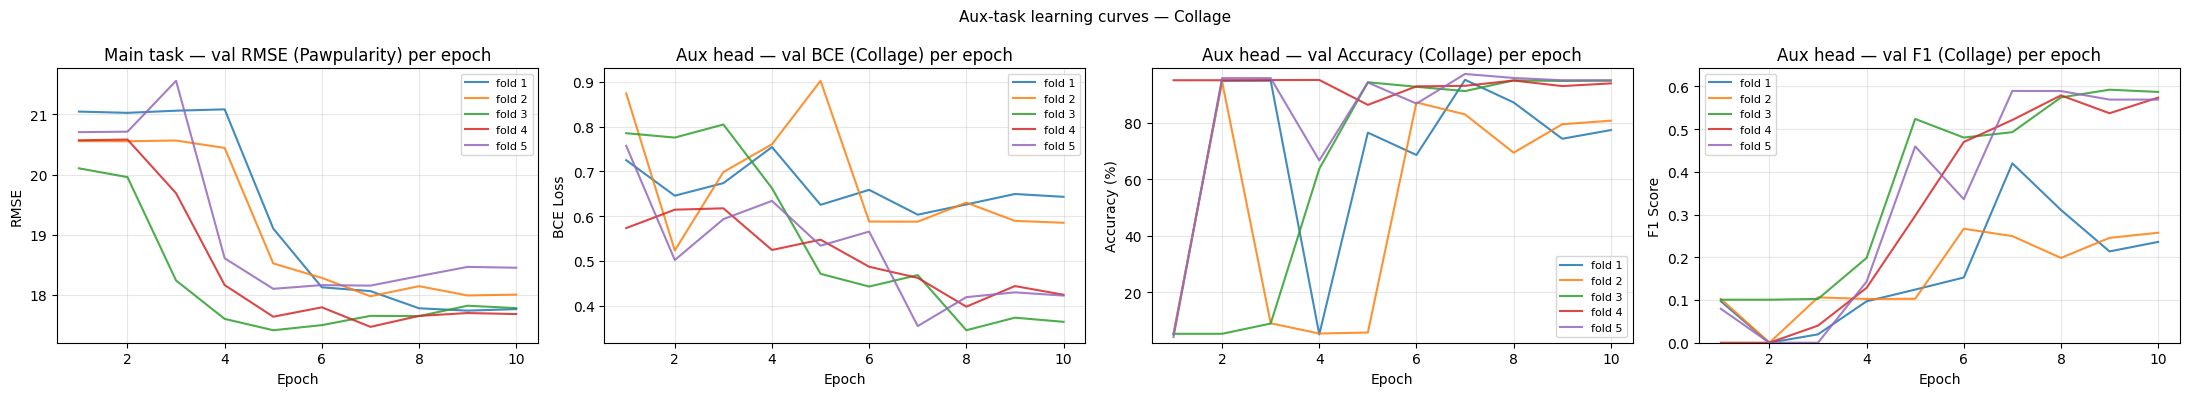

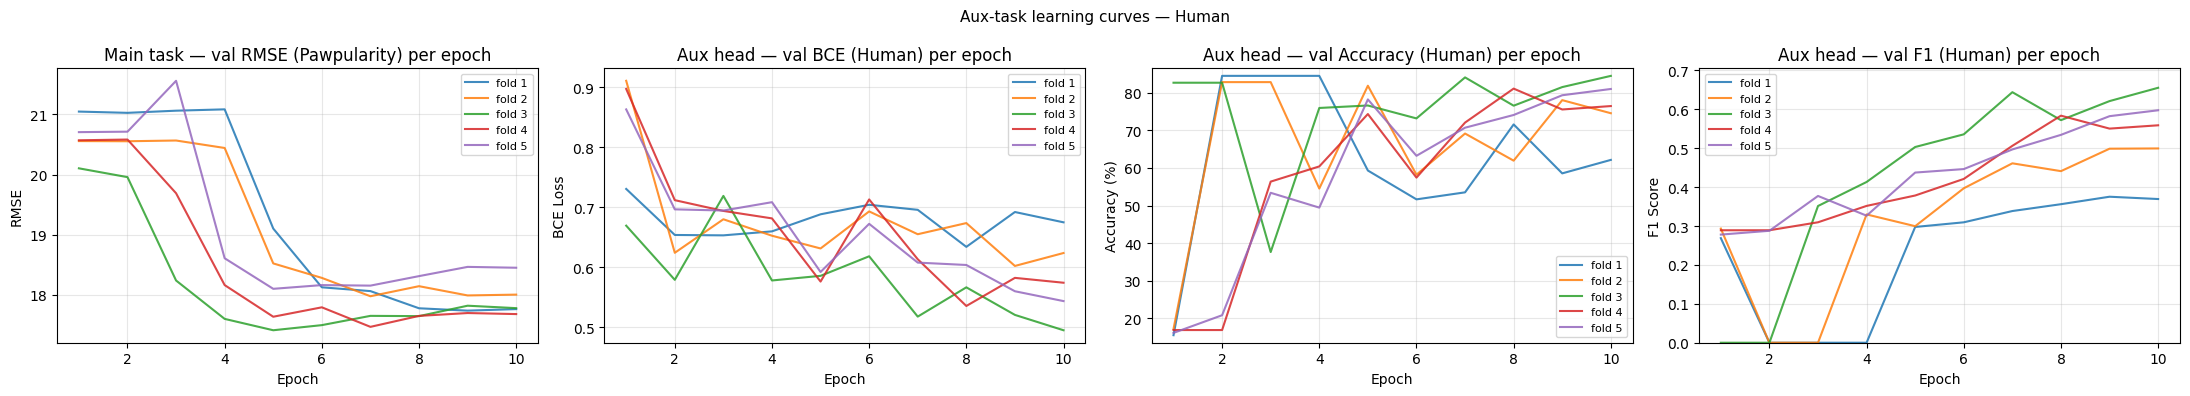

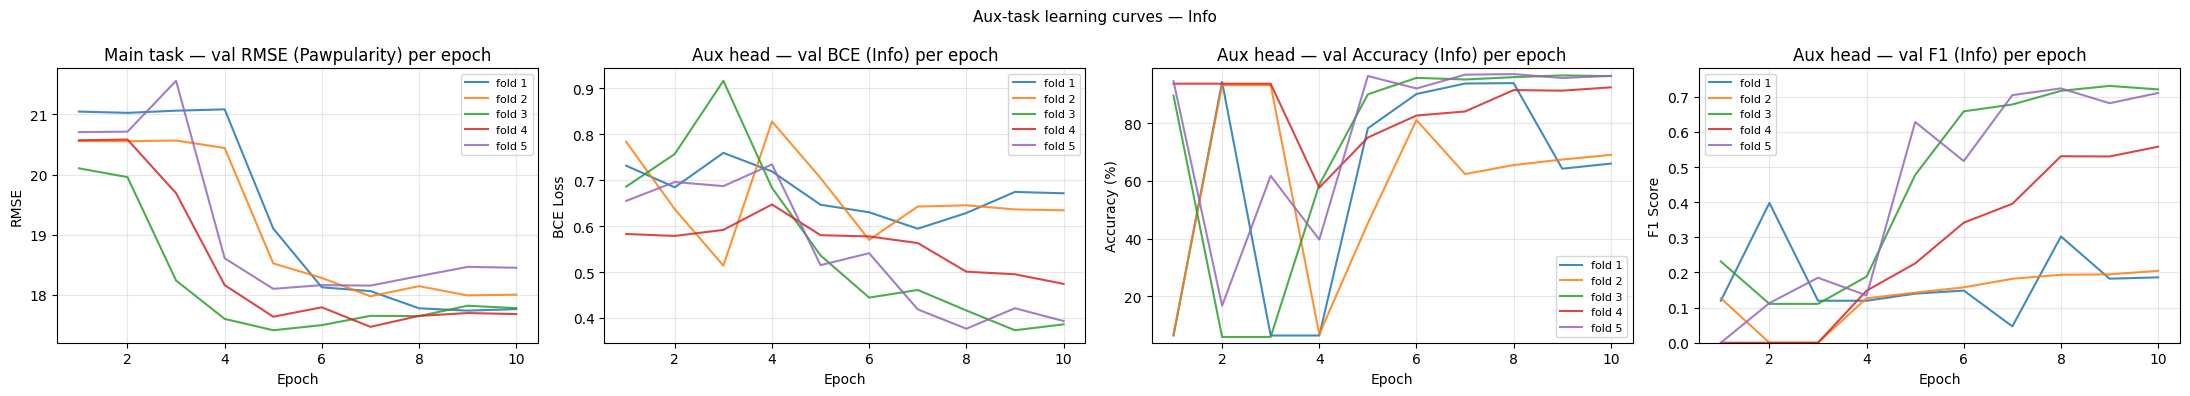

In [10]:
from src.plot import plot_metadata_aux_curves

BACKBONE = "swin_large_patch4_window12_384"
IMG_SIZE  = 384

# plot curves
plot_metadata_aux_curves(
    out_dir=out_dir,
    binary_aux_tasks=cfg["binary_aux_tasks"],
)

### Side by Side Comparison with Image only

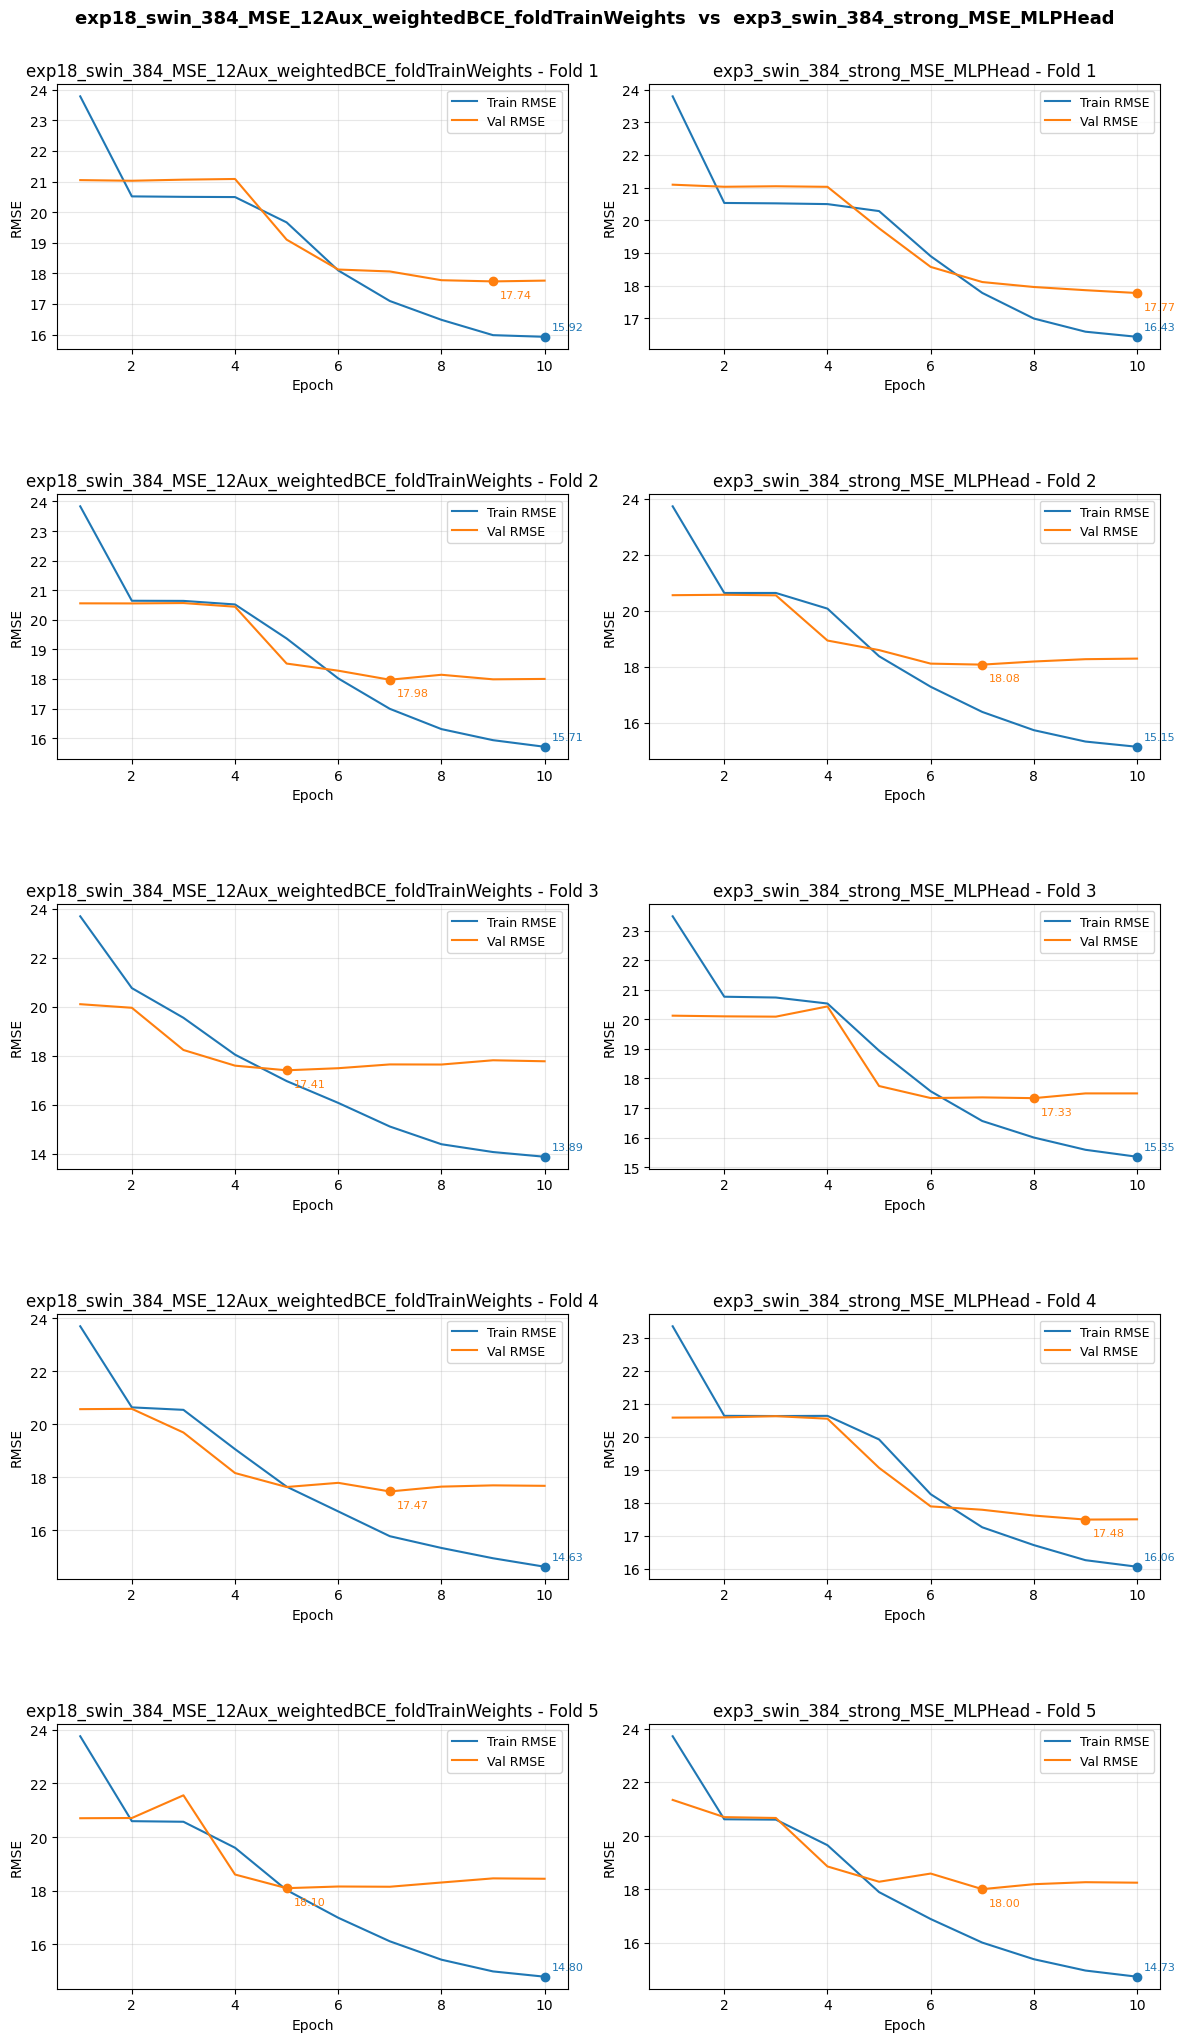

In [11]:
### Side by Side Comparison with Concatenation based Feature Fusion Exp4
from src.plot import plot_compare_two_experiments
plot_compare_two_experiments(out_dir, out_dir1,folds=[1,2,3,4,5], label_a=exp_name, label_b="exp3_swin_384_strong_MSE_MLPHead")


In [12]:
#  Inspect worst error rows

errors_path = os.path.join(out_dir, "top50_errors.csv")
err_df = pd.read_csv(errors_path)
err_df.head()

,Id,fold,ytrue,oof_pred,abs_err
0,4435d6f98ad72782ca0cf61f946b016d,5,100,26.967640,73.032360
1,48a66727373de4e7fa7bb3331cd9acc8,3,96,23.567087,72.432913
2,deb8d1618d0cdc2a78c8198b882ebb2b,3,100,28.402351,71.597649
3,1e59bc4bf0f630df8f17fb908b7c13c2,1,100,29.492832,70.507168
4,12b136b947a64c8b23e3929f70b41933,1,100,29.728979,70.271021


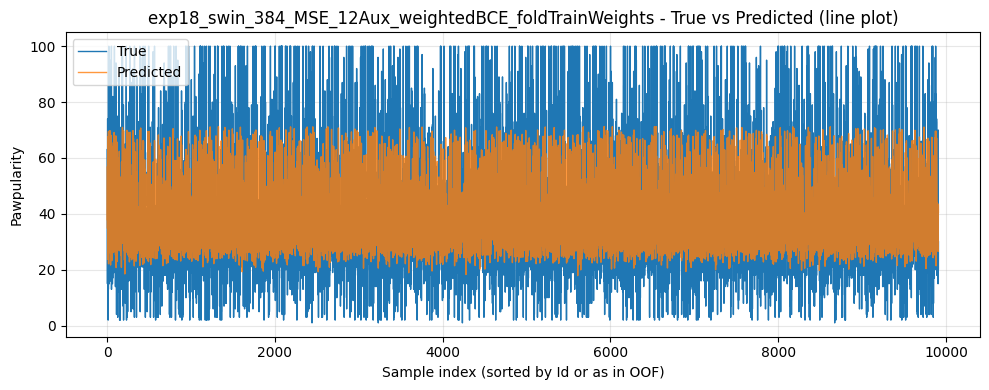

In [13]:
import os
import pandas as pd
from src.plot import (
   plot_oof_true_pred_lines,
    show_images_grid,
)

# Load OOF detail and top-errors
oof_df = pd.read_csv(os.path.join(out_dir, "oof_detail.csv"))
err_df = pd.read_csv(os.path.join(out_dir, "top50_errors.csv"))

# Plot
plot_oof_true_pred_lines(oof_df, title_prefix=exp_name)





exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights OOF RMSE: 17.739282264726377
exp3_swin_384_strong_MSE_MLPHead OOF RMSE: 17.73602090865089
ΔRMSE (exp3_swin_384_strong_MSE_MLPHead - exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights): -0.003261356075487498


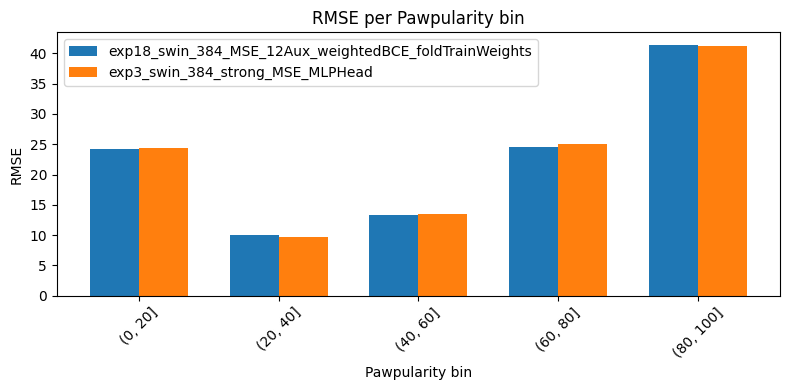

In [14]:
from src.plot import compare_oof_by_bins
bins = [0, 20, 40, 60, 80, 100]

df_bins, rmse3_all, rmse5_all, gap = compare_oof_by_bins(
    oof_path_a=os.path.join(out_dir, "oof_detail.csv"),
    oof_path_b=os.path.join(out_dir1, "oof_detail.csv"),
    bins=bins,
    label_a=exp_name,
    label_b="exp3_swin_384_strong_MSE_MLPHead",
    title_prefix="",
)

In [15]:
df_bins.head()

,bin,count,exp18_swin_384_MSE_12Aux_weightedBCE_foldTrainWeights_rmse,exp3_swin_384_strong_MSE_MLPHead_rmse,rmse_diff,winner
0,"(0, 20]",1417,24.254422,24.383091,0.128668,exp18_swin_384_MSE_12Aux_weightedBCE_foldTrain...
1,"(20, 40]",5119,10.059304,9.719382,-0.339922,exp3_swin_384_strong_MSE_MLPHead_better
2,"(40, 60]",2088,13.276368,13.504186,0.227818,exp18_swin_384_MSE_12Aux_weightedBCE_foldTrain...
3,"(60, 80]",727,24.539542,25.028708,0.489166,exp18_swin_384_MSE_12Aux_weightedBCE_foldTrain...
4,"(80, 100]",561,41.404160,41.275555,-0.128604,exp3_swin_384_strong_MSE_MLPHead_better


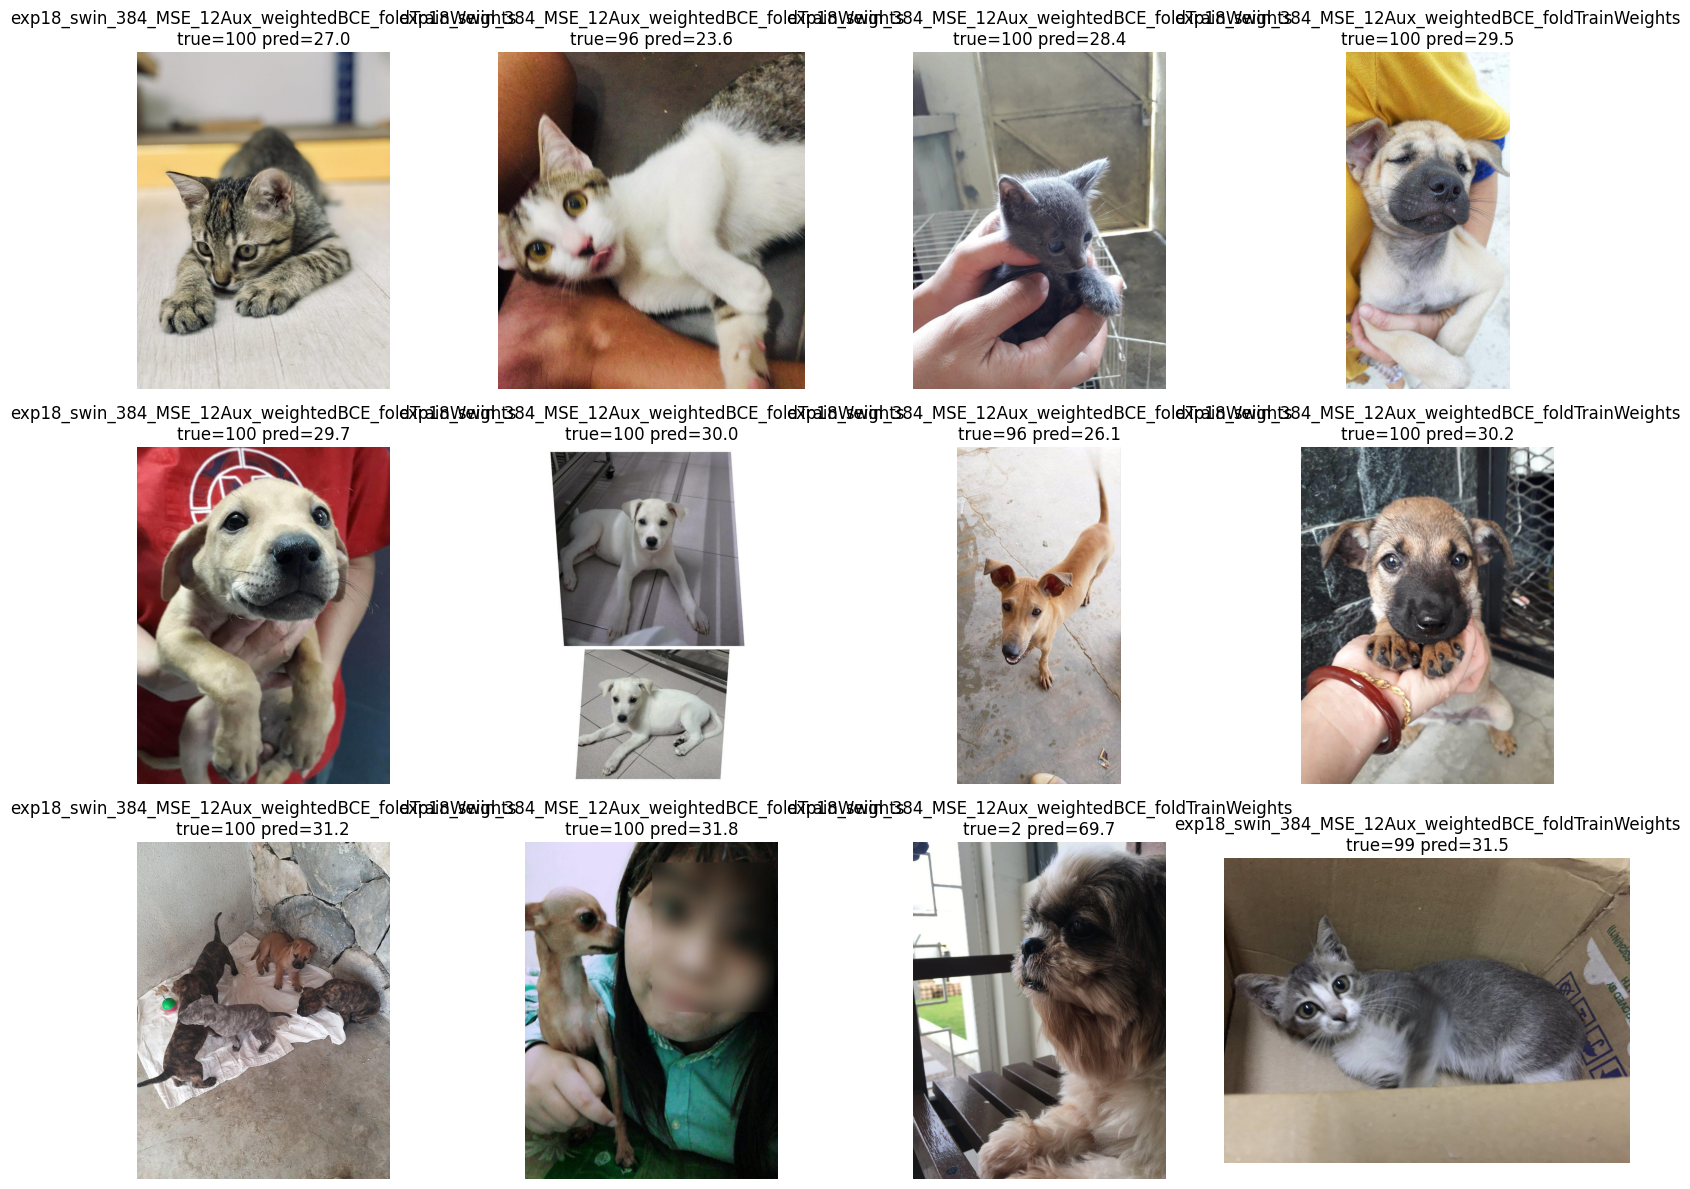

In [16]:
# Images of worst errors
img_folder = os.path.join(main_folder, "data", "train")
show_images_grid(err_df, img_folder, n=12, title_prefix=exp_name)

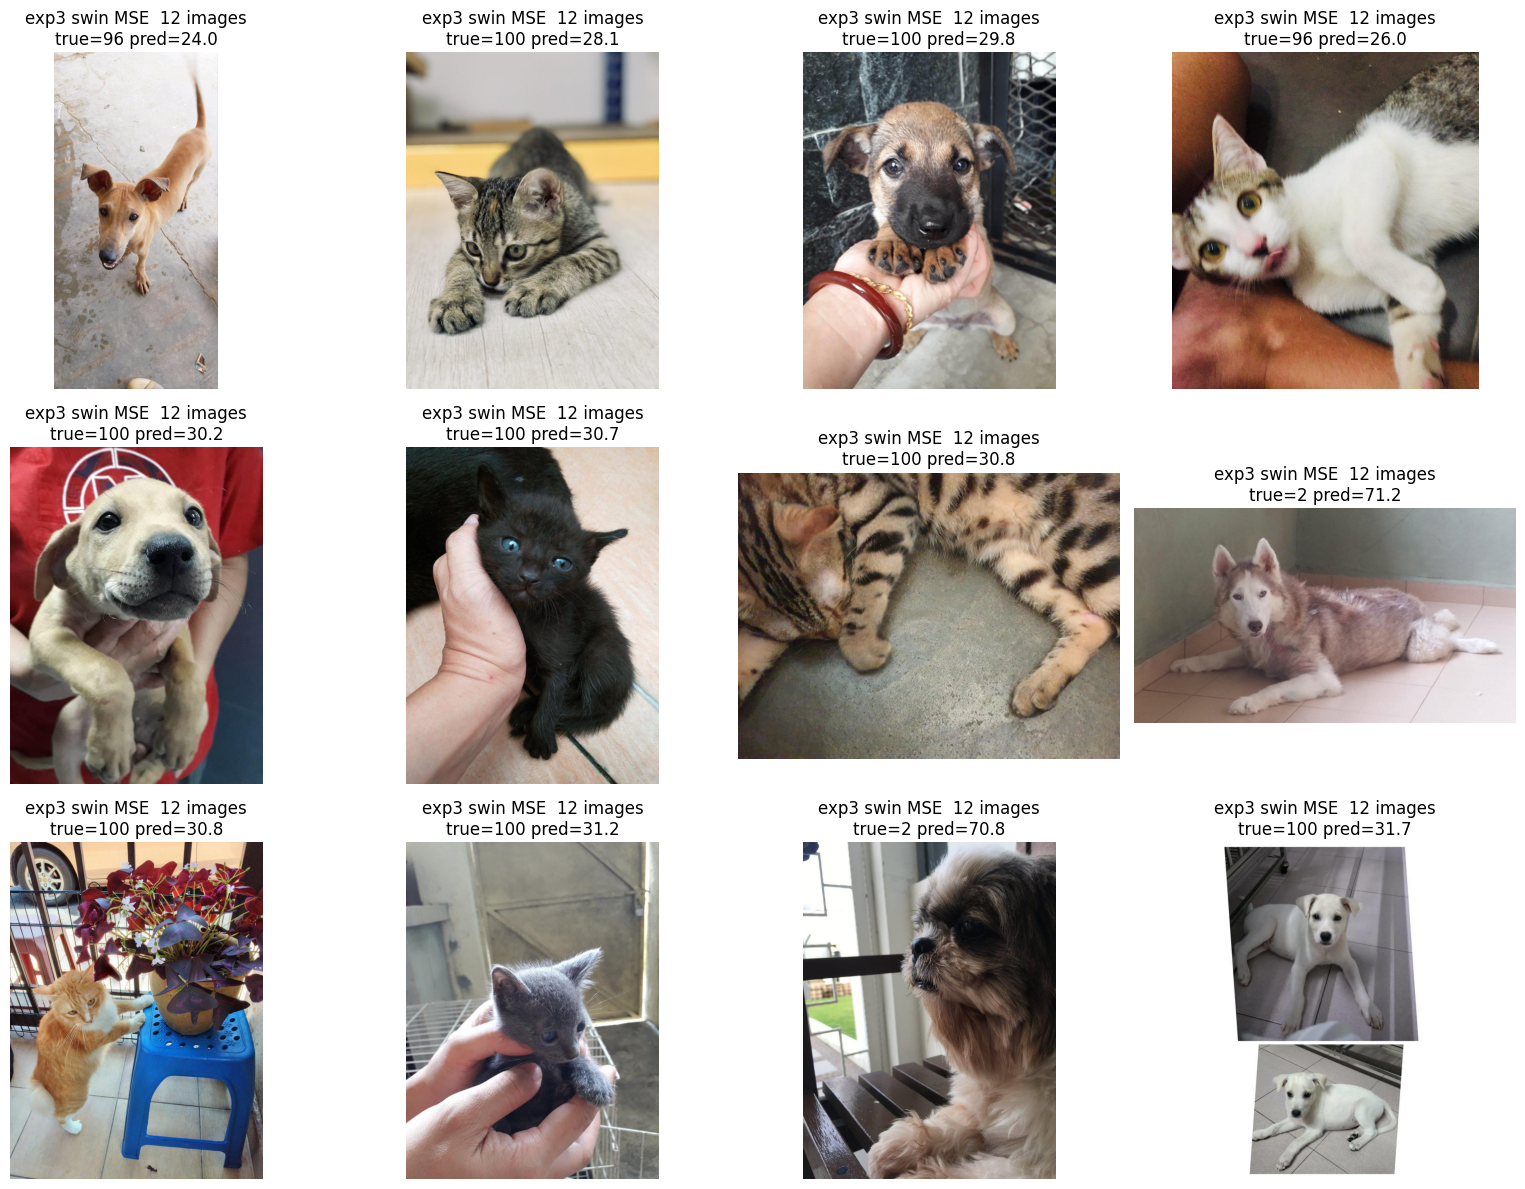

In [17]:
# Load OOF detail and top-errors of Exp4 
oof_df1 = pd.read_csv(os.path.join(out_dir1, "oof_detail.csv"))
err_df1 = pd.read_csv(os.path.join(out_dir1, "top50_errors.csv"))
show_images_grid(err_df1, img_folder, n=12, title_prefix="exp3 swin MSE  12 images")